In [6]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from itertools import combinations

import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

In [7]:
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /Users/kavya/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /Users/kavya/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [8]:
DATA_DIR = Path("../data/raw")

articles = {}

for file in sorted(DATA_DIR.glob("*.txt")):

    with open(file, "r", encoding="utf-8") as f:
        articles[file.stem] = f.read()

print("Total articles loaded:", len(articles))

Total articles loaded: 3


In [9]:
for article_id, text in articles.items():

    print("\n" + "=" * 80)
    print("ARTICLE:", article_id)
    print("=" * 80)

    print(text)


ARTICLE: article_01
Headline: Heavy Rainfall Causes Flooding Across Riverton Publication
date: 2026-08-14 Source: The Riverton Herald

Continuous rainfall began across Riverton late on August 13, causing
several streets in the eastern part of the city to flood by early Friday
morning. The city weather office recorded 118 millimetres of rain in
twelve hours.

Emergency services received their first major flooding calls at
approximately 5:30 a.m. on August 14. Water entered ground-floor homes
in the Riverside neighbourhood, and traffic was diverted from the Old
Bridge.

The municipal corporation opened two temporary shelters at Central High
School and the Riverside Community Hall. Officials said that 46
residents had been moved to the shelters by 10 a.m.

The weather office warned that further rainfall was expected through
Saturday. Residents were advised to avoid underpasses and roads near the
river.


ARTICLE: article_02
Headline: Schools Closed as Riverton River Level Rises Publicati

In [10]:
df = pd.DataFrame([
    {
        "article_id": article_id,
        "text": text
    }
    for article_id, text in articles.items()
])

df.head()

,article_id,text
0,article_01,Headline: Heavy Rainfall Causes Flooding Acros...
1,article_02,Headline: Schools Closed as Riverton River Lev...
2,article_03,Headline: Power Supply Restored in Parts of Fl...


In [11]:
print("DATASET OVERVIEW")
print("-" * 40)

print("Number of articles:", len(df))

total_words = sum(len(text.split()) for text in df["text"])

print("Total words:", total_words)

print("Total characters:",
      sum(len(text) for text in df["text"]))

print("Average words per article:",
      round(total_words / len(df), 2))

DATASET OVERVIEW
----------------------------------------
Number of articles: 3
Total words: 431
Total characters: 2825
Average words per article: 143.67


In [12]:
article_stats = []

for article_id, text in articles.items():

    sentences = sent_tokenize(text)

    article_stats.append({
        "article_id": article_id,
        "word_count": len(text.split()),
        "character_count": len(text),
        "sentence_count": len(sentences)
    })

stats_df = pd.DataFrame(article_stats)

stats_df

,article_id,word_count,character_count,sentence_count
0,article_01,134,893,8
1,article_02,139,900,8
2,article_03,158,1032,8


In [13]:
sentences = []

for article_id, text in articles.items():

    article_sentences = sent_tokenize(text)

    for i, sentence in enumerate(article_sentences):

        sentences.append({
            "article_id": article_id,
            "sentence_id": i + 1,
            "sentence": sentence
        })

sent_df = pd.DataFrame(sentences)

print("Total sentences:", len(sent_df))

sent_df.head(20)

Total sentences: 24


,article_id,sentence_id,sentence
0,article_01,1,Headline: Heavy Rainfall Causes Flooding Acros...
1,article_01,2,The city weather office recorded 118 millimetr...
2,article_01,3,Emergency services received their first major ...
3,article_01,4,Water entered ground-floor homes\nin the River...
4,article_01,5,The municipal corporation opened two temporary...
5,article_01,6,Officials said that 46\nresidents had been mov...
6,article_01,7,The weather office warned that further rainfal...
7,article_01,8,Residents were advised to avoid underpasses an...
8,article_02,1,Headline: Schools Closed as Riverton River Lev...
9,article_02,2,The decision was\nannounced at 7:15 a.m. after...


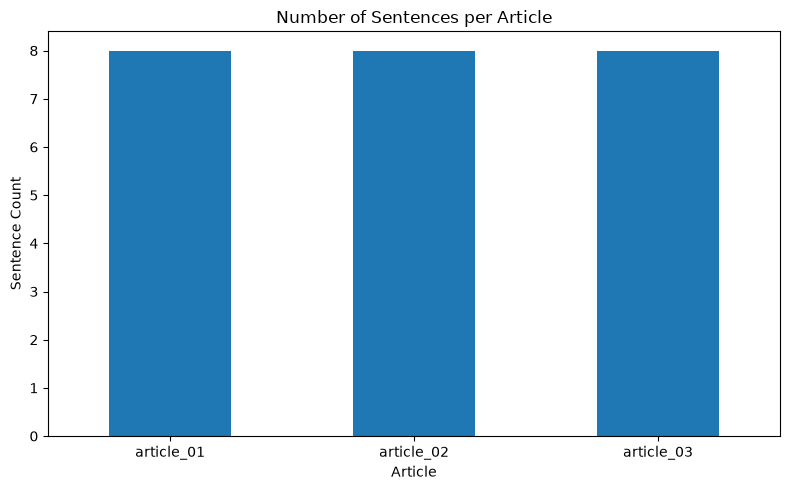

In [14]:
plt.figure(figsize=(8, 5))

sent_df.groupby("article_id").size().plot(kind="bar")

plt.title("Number of Sentences per Article")
plt.xlabel("Article")
plt.ylabel("Sentence Count")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [15]:
stop_words = set(stopwords.words("english"))

all_words = []

for text in articles.values():

    words = word_tokenize(text.lower())

    words = [
        word for word in words
        if word.isalpha() and word not in stop_words
    ]

    all_words.extend(words)

word_freq = Counter(all_words)

freq_df = pd.DataFrame(
    word_freq.most_common(20),
    columns=["Word", "Frequency"]
)

freq_df

,Word,Frequency
0,riverton,8
1,riverside,6
2,rainfall,5
3,august,4
4,city,4
5,weather,4
6,office,4
7,bridge,4
8,municipal,4
9,shelters,4


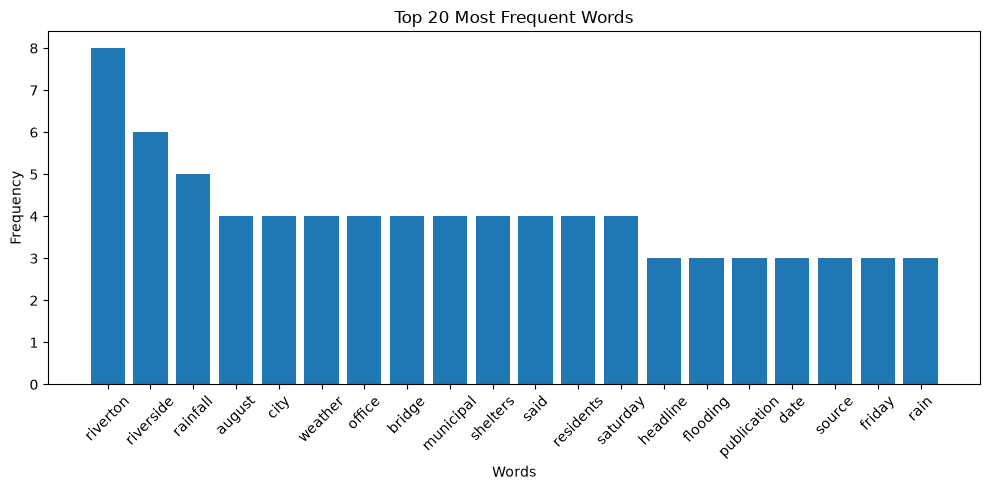

In [16]:
plt.figure(figsize=(10, 5))

plt.bar(freq_df["Word"], freq_df["Frequency"])

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
article_words = {}

for article_id, text in articles.items():

    words = set(
        word for word in word_tokenize(text.lower())
        if word.isalpha() and word not in stop_words
    )

    article_words[article_id] = words

In [18]:
similarity_results = []

for a1, a2 in combinations(article_words.keys(), 2):

    set1 = article_words[a1]
    set2 = article_words[a2]

    intersection = set1 & set2
    union = set1 | set2

    similarity = len(intersection) / len(union)

    similarity_results.append({
        "Article 1": a1,
        "Article 2": a2,
        "Common Words": len(intersection),
        "Jaccard Similarity": round(similarity, 4)
    })

similarity_df = pd.DataFrame(similarity_results)

similarity_df

,Article 1,Article 2,Common Words,Jaccard Similarity
0,article_01,article_02,34,0.2906
1,article_01,article_03,38,0.3248
2,article_02,article_03,36,0.2857


In [20]:
def extract_article_metadata(article_id, text):

    # Normalize whitespace in the header, but preserve original body
    parts = re.split(r"\n\s*\n", text.strip(), maxsplit=1)

    header = parts[0] if parts else ""
    content = parts[1].strip() if len(parts) > 1 else ""

    metadata = {
        "article_id": article_id,
        "headline": None,
        "publication_date": None,
        "source": None,
        "content": content if content else text.strip()
    }

    # Extract headline
    headline_match = re.search(
        r"Headline\s*:\s*(.*?)(?=\s+Publication\s*date\s*:)",
        header,
        re.IGNORECASE | re.DOTALL
    )

    if headline_match:
        metadata["headline"] = headline_match.group(1).strip()

    # Extract publication date
    date_match = re.search(
        r"Publication\s*date\s*:\s*(\d{4}-\d{2}-\d{2})",
        header,
        re.IGNORECASE
    )

    if date_match:
        metadata["publication_date"] = date_match.group(1)

    # Extract source
    source_match = re.search(
        r"Source\s*:\s*(.*?)(?=\s*$)",
        header,
        re.IGNORECASE | re.DOTALL
    )

    if source_match:
        metadata["source"] = source_match.group(1).strip()

    return metadata


article_data = [
    extract_article_metadata(article_id, text)
    for article_id, text in articles.items()
]

articles_df = pd.DataFrame(article_data)

articles_df

,article_id,headline,publication_date,source,content
0,article_01,Heavy Rainfall Causes Flooding Across Riverton,2026-08-14,The Riverton Herald,Continuous rainfall began across Riverton late...
1,article_02,Schools Closed as Riverton River Level Rises,2026-08-14,National Daily News,Heavy rainfall continued in Riverton on Friday...
2,article_03,Power Supply Restored in Parts of Flood-Hit Ri...,2026-08-15,City News Network,"Rainfall eased in Riverton on Saturday, August..."


In [21]:
articles_df["publication_date"] = pd.to_datetime(
    articles_df["publication_date"],
    errors="coerce"
)

In [22]:
from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

articles_df.to_csv(
    OUTPUT_DIR / "articles_metadata.csv",
    index=False
)

print("DataFrame saved successfully!")

DataFrame saved successfully!
